<a href="https://colab.research.google.com/github/ddev3r/Machine-learning/blob/main/C%D1%82%D0%B0%D1%80%D0%BE%D0%B2%D0%BE%D0%B9%D1%82%D0%BE%D0%B2_%D0%9F%D0%A0_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Варіант №20**

**Завдання 1**

№1 Вивести перших 5 рядків.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

#Diabetes Dataset
diabetes = load_diabetes(as_frame=True)

df = diabetes.frame.copy()

print("Розмір датасету:", df.shape)
print("\nПерші 5 рядків:")
display(df.head())

Розмір датасету: (442, 11)

Перші 5 рядків:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


№2 Перевірити наявність пропусків. У разі виявлення замінити на
середнє значення.

In [2]:
print("Початкова кількість пропусків:")
print(df.isnull().sum())

# Заміна на сер. знач.
for column in df.columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].mean())

print("\nКінцева кількість пропусків:")
print(df.isnull().sum())

Початкова кількість пропусків:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Кінцева кількість пропусків:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


№3 Перевірити наявність дублікатів, при виявленні – видалити.

In [3]:
print("Дублікатів:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Кількість рядків після видалення дублікатів:", len(df))
print("Дублікатів після обробки:", df.duplicated().sum())

Дублікатів: 0
Кількість рядків після видалення дублікатів: 442
Дублікатів після обробки: 0


№4 Замінити бінарні ознаки. У стовпчику «стать» спочатку перевірте
унікальні значення.

In [5]:
print("Унікальні значення:")
print(df["sex"].unique())

print("\nКількість кожного значення:")
print(df["sex"].value_counts())

print("\nІнші унікальні значення:")
print("s1:", df["s1"].nunique())
print("s2:", df["s2"].nunique())

Унікальні значення:
[ 0.05068012 -0.04464164]

Кількість кожного значення:
sex
-0.044642    235
 0.050680    207
Name: count, dtype: int64

Інші унікальні значення:
s1: 141
s2: 302


№5 Перевірити тип даних. При необхідності замінити тип даних на
числовий.

In [6]:
print("Типи даних:")
print(df.dtypes)

for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("\nТипи даних після обробки:")
print(df.dtypes)

Типи даних:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

Типи даних після обробки:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object


№6 Обчислити кореляцію між прогресом діабету і іншмим ознаками.

Розташувати в порядку спадання.

Побудувати теплову карту кореляції.

Кореляція ознак із прогресом діабету:


,Кореляція з target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


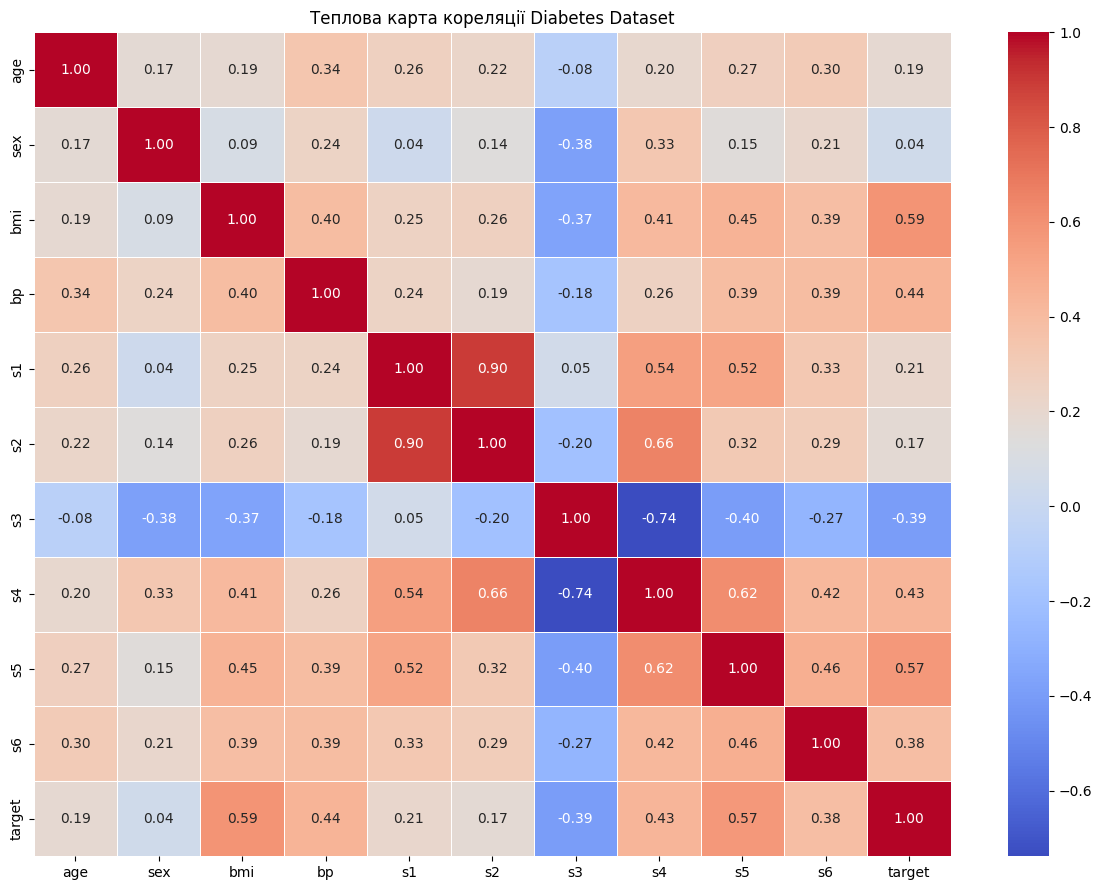

In [8]:
correlations = df.corr(numeric_only=True)["target"].drop("target")

# В порядку спадання
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

print("Кореляція ознак із прогресом діабету:")
display(correlations.to_frame(name="Кореляція з target"))
plt.title("Теплова карта кореляції Diabetes Dataset")
plt.tight_layout()
plt.show()

№7 Масштабувати ознаки.

In [10]:
X = df.drop(columns=["target"])
y = df["target"]

print("Ознаки:", X.shape)
print("Змінна:", y.shape)

Ознаки: (442, 10)
Змінна: (442,)


№8 Поділити дані на тренувальну і тестову вибірки

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=123
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір тренувальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір тренувальної вибірки: (221, 10)
Розмір тестової вибірки: (221, 10)


№9 Побудувати модель лінійной регресії і RandomForest регресії на
основі більш корелюючих ознак (підібрати оптимальне число).

In [23]:
feature_order = correlations.abs().sort_values(
    ascending=False
).index.tolist()

results_diabetes = []

for n_features in range(1, len(feature_order) + 1):

    selected_features = feature_order[:n_features]

    X_train_selected = X_train[selected_features]
    X_test_selected = X_test[selected_features]

    scaler_temp = StandardScaler()

    X_train_temp = scaler_temp.fit_transform(X_train_selected)
    X_test_temp = scaler_temp.transform(X_test_selected)

    # Лінійна регресія
    linear_model = LinearRegression()
    linear_model.fit(X_train_temp, y_train)

    linear_pred = linear_model.predict(X_test_temp)

    results_diabetes.append({
        "Модель": "Linear Regression",
        "Кількість ознак": n_features,
        "R2": r2_score(y_test, linear_pred),
        "MSE": mean_squared_error(y_test, linear_pred)
    })

    # Випадковий ліс
    rf_model = RandomForestRegressor(
        n_estimators=150,
        random_state=123,
        n_jobs=-1
    )

    rf_model.fit(X_train_selected, y_train)

    rf_pred = rf_model.predict(X_test_selected)

    results_diabetes.append({
        "Модель": "Random Forest",
        "Кількість ознак": n_features,
        "R2": r2_score(y_test, rf_pred),
        "MSE": mean_squared_error(y_test, rf_pred)
    })

results_diabetes_df = pd.DataFrame(results_diabetes)

best_linear = (
    results_diabetes_df[
        results_diabetes_df["Модель"] == "Linear Regression"
    ]
    .sort_values("R2", ascending=False)
    .iloc[0]
)

best_rf = (
    results_diabetes_df[
        results_diabetes_df["Модель"] == "Random Forest"
    ]
    .sort_values("R2", ascending=False)
    .iloc[0]
)


print("Результати для різної кількості ознак:")
display(results_diabetes_df.round(4))
print("Найкращий результат Linear Regression:")
display(best_linear.to_frame().round(4))
print("Найкращий результат Random Forest:")
display(best_rf.to_frame().round(4))

Результати для різної кількості ознак:


,Модель,Кількість ознак,R2,MSE
0,Linear Regression,1,0.2549,4460.9555
1,Random Forest,1,0.0692,5573.1037
2,Linear Regression,2,0.4069,3551.3491
3,Random Forest,2,0.2852,4279.7151
4,Linear Regression,3,0.4369,3371.2934
5,Random Forest,3,0.3661,3795.5415
6,Linear Regression,4,0.4318,3402.2638
7,Random Forest,4,0.3589,3838.4080
8,Linear Regression,5,0.4477,3306.7838
9,Random Forest,5,0.3611,3825.2289


Найкращий результат Linear Regression:


,8
Модель,Linear Regression
Кількість ознак,5
R2,0.447711
MSE,3306.783807


Найкращий результат Random Forest:


,19
Модель,Random Forest
Кількість ознак,10
R2,0.423231
MSE,3453.357864


№10 Вивести коефіцієнт детермінації і середньоквадратичну помилку.

In [26]:
# Оптимальна к-ість ознак
n_linear = int(best_linear["Кількість ознак"])
n_rf = int(best_rf["Кількість ознак"])

features_linear = feature_order[:n_linear]
features_rf = feature_order[:n_rf]

#LR
X_train_linear = X_train[features_linear]
X_test_linear = X_test[features_linear]

scaler_linear = StandardScaler()

X_train_linear_scaled = scaler_linear.fit_transform(X_train_linear)
X_test_linear_scaled = scaler_linear.transform(X_test_linear)

linear_model = LinearRegression()
linear_model.fit(X_train_linear_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_linear_scaled)

#RF
X_train_rf = X_train[features_rf]
X_test_rf = X_test[features_rf]

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train)

y_pred_rf = rf_model.predict(X_test_rf)

# Оцінювання моделей
print("Linear regression")
print("Кількість ознак:", n_linear)
print("Коеф. детермінації:", round(r2_score(y_test, y_pred_linear), 4))
print("Середньоквадратична помилка:", round(mean_squared_error(y_test, y_pred_linear), 4))

print("\nRandom forest")
print("Кількість ознак:", n_rf)
print("Коеф. детермінації:", round(r2_score(y_test, y_pred_rf), 4))
print("Середньоквадратична помилка:", round(mean_squared_error(y_test, y_pred_rf), 4))

Linear regression
Кількість ознак: 5
Коеф. детермінації: 0.4477
Середньоквадратична помилка: 3306.7838

Random forest
Кількість ознак: 10
Коеф. детермінації: 0.4217
Середньоквадратична помилка: 3462.6967


Порівняння моделей за R²

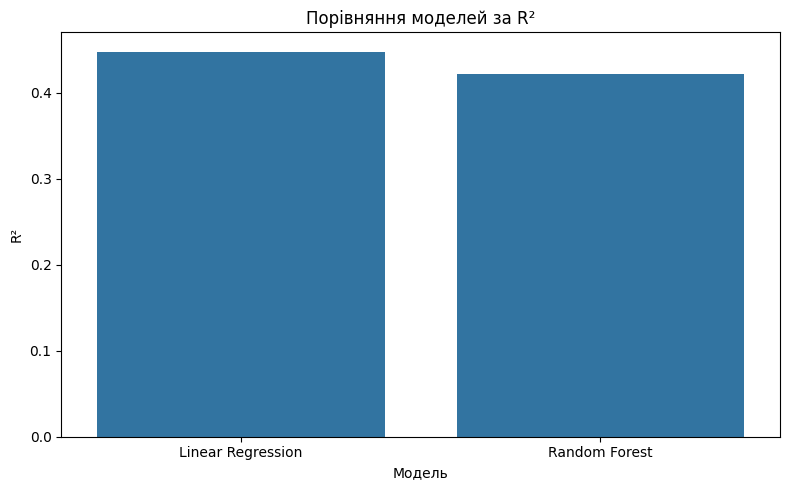

In [31]:
comparison_diabetes = pd.DataFrame({
    "Модель": ["Linear Regression", "Random Forest"],
    "R2": [
        r2_score(y_test, y_pred_linear),
        r2_score(y_test, y_pred_rf)
    ]
})

plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison_diabetes,
    x="Модель",
    y="R2"
)

plt.title("Порівняння моделей за R²")
plt.ylabel("R²")
plt.xlabel("Модель")
plt.tight_layout()
plt.show()

Порівняння моделей за MSE

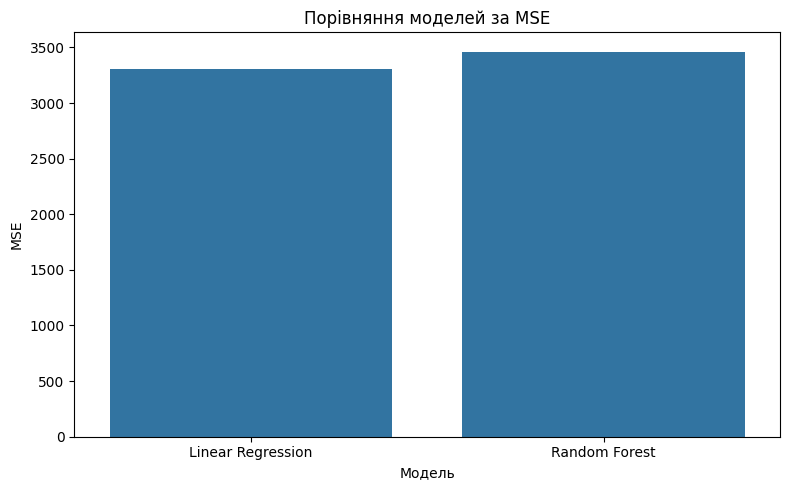

In [30]:
comparison_diabetes["MSE"] = [
    mean_squared_error(y_test, y_pred_linear),
    mean_squared_error(y_test, y_pred_rf)
]

plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison_diabetes,
    x="Модель",
    y="MSE"
)

plt.title("Порівняння моделей за MSE")
plt.ylabel("MSE")
plt.xlabel("Модель")
plt.tight_layout()
plt.show()

№11 Вивести справжні і прогнозовані значення.

In [33]:
predictions_diabetes = pd.DataFrame({
    "Справжнє значення": y_test.to_numpy(),
    "Прогноз Linear Regression": y_pred_linear,
    "Прогноз Random Forest": y_pred_rf
})

display(predictions_diabetes.head(20).round(2))

,Справжнє значення,Прогноз Linear Regression,Прогноз Random Forest
0,185.0,166.75,146.49
1,150.0,150.01,145.06
2,246.0,207.62,219.88
3,184.0,166.76,155.80
4,110.0,159.56,172.25
5,202.0,162.77,139.67
6,336.0,256.96,277.68
7,69.0,132.68,133.48
8,69.0,139.69,171.42
9,87.0,85.29,112.38


Графік справжніх і прогнозованих значень

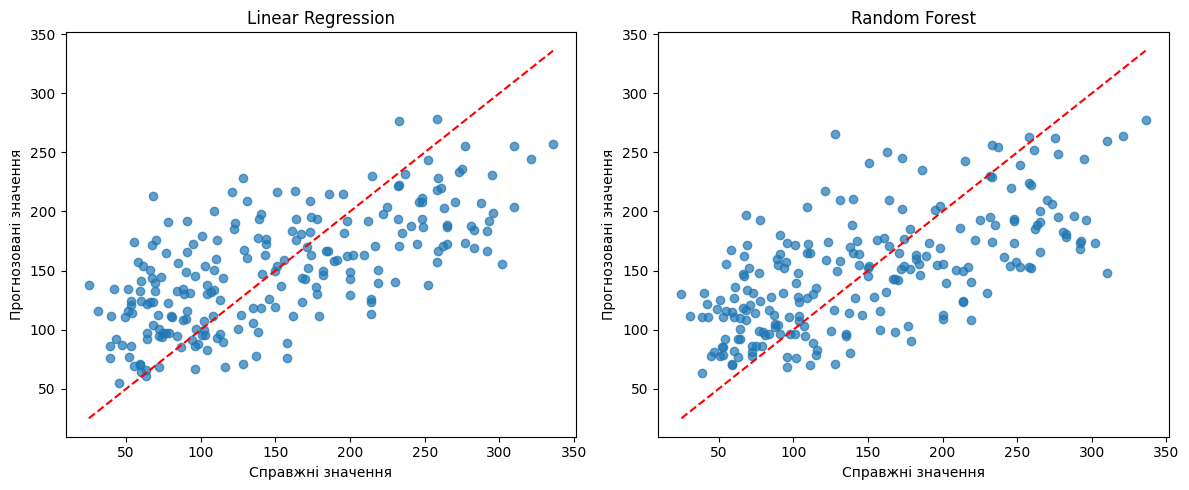

In [34]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_linear, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Справжні значення")
plt.ylabel("Прогнозовані значення")
plt.title("Linear Regression")

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_rf, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Справжні значення")
plt.ylabel("Прогнозовані значення")
plt.title("Random Forest")

plt.tight_layout()
plt.show()

Висновок: У ході виконання першого завдання було проаналізовано набір даних Diabetes Dataset: перевірено структуру, пропуски та дублікати, досліджено кореляцію ознак із цільовою змінною і побудовано теплову карту. Після поділу даних на тренувальну й тестову вибірки та масштабування ознак на основі трьох найбільш корельованих параметрів було навчено дві моделі регресії.

За результатами оцінювання Linear Regression отримала R² = 0,4477 і MSE = 3306.7838, а Random Forest — R² = 0,4217 і MSE = 3462.6967. Лінійна регресія показала дещо кращий результат, проте загальна точність прогнозування обох моделей залишається помірною, що підтвердили графіки та таблиця прогнозів.

**Завдання №2**

Завантажити датасет California Housing Dataset, що містить інформацію
про житло в Каліфорнії. Вивести перших 5 рядків.

In [35]:
import pandas as pd

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df_california = pd.read_csv(url)

df_california = df_california.rename(
    columns={"median_house_value": "MedHouseVal"}
)

# Переведення цільової змінної у сумісний формат
df_california["MedHouseVal"] = (
    df_california["MedHouseVal"] / 100000
)

print("Розмір датасету:", df_california.shape)
print("\nПерші 5 рядків:")
display(df_california.head())

Розмір датасету: (20640, 10)

Перші 5 рядків:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,MedHouseVal,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,4.526,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,3.585,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,3.521,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,3.413,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,3.422,NEAR BAY


№1 Перевірити наявність пропусків. У разі виявлення замінити на
середнє значення.

In [44]:

print("Кількість пропусків:")
print(df_california.isnull().sum())

for column in df_california.columns:
    if df_california[column].isnull().any():
        df_california[column] = df_california[column].fillna(
            df_california[column].mean()
        )

print("\nПропуски після обробки:")
print(df_california.isnull().sum())


Кількість пропусків:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
MedHouseVal           0
ocean_proximity       0
dtype: int64

Пропуски після обробки:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
MedHouseVal           0
ocean_proximity       0
dtype: int64


№2 Перевірити наявність дублікатів, при виявленні – видалити.

In [43]:
print("Кількість дублікатів:")
print(df_california.duplicated().sum())

# Видалення
df_california = df_california.drop_duplicates().reset_index(drop=True)

Кількість дублікатів:
0


№3 Перевірити тип даних.

In [42]:
print("Типи даних:")
print(df_california.dtypes)

Типи даних:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
MedHouseVal           float64
ocean_proximity        object
dtype: object


№4 Обчислити кореляцію. Розташувати в порядку спадання. Побудувати теплову карту.

Кореляція ознак із MedHouseVal:


,MedHouseVal
median_income,0.688075
latitude,-0.144160
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049454
longitude,-0.045967
population,-0.024650


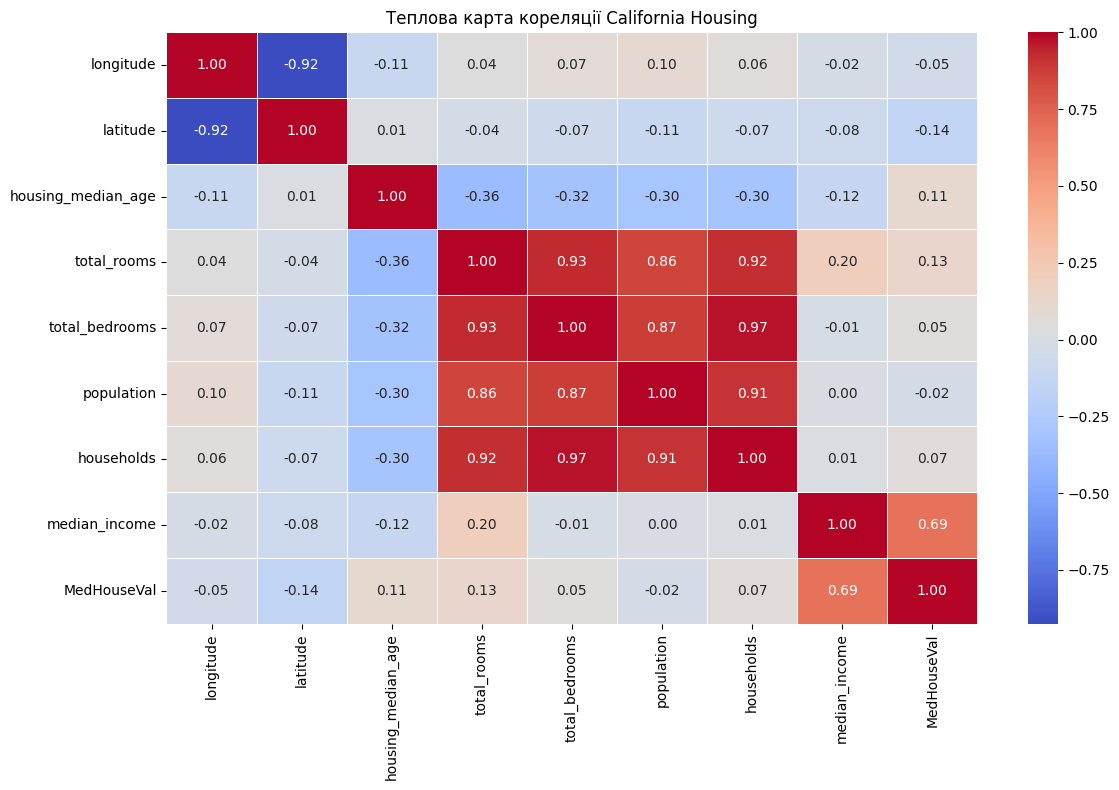

In [48]:
correlations_california = (
    df_california.corr(numeric_only=True)["MedHouseVal"]
    .drop("MedHouseVal")
)

correlations_california = correlations_california.reindex(
    correlations_california.abs().sort_values(
        ascending=False
    ).index
)
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_california.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

print("Кореляція ознак із MedHouseVal:")
display(
    correlations_california.to_frame()
)
plt.title("Теплова карта кореляції California Housing")
plt.tight_layout()
plt.show()

№5 Поділити дані на тренувальні і тестові.

In [50]:
X_cal = df_california.drop(columns=["MedHouseVal"])
y_cal = df_california["MedHouseVal"]

X_train_cal, X_test_cal, y_train_cal, y_test_cal = train_test_split(
    X_cal,
    y_cal,
    test_size=0.5,
    random_state=123
)

print("Тренувальна вибірка:", X_train_cal.shape)
print("Тестова вибірка:", X_test_cal.shape)

Тренувальна вибірка: (10320, 9)
Тестова вибірка: (10320, 9)


№6 Побудувати 3 моделі: лін. Регресія, регресія випадковий ліс, Ridge.
Підібрати оптимальні параметри за допомогою GridSeach.

In [52]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Визначення ознак
numeric_features = X_train_cal.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_cal.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Числові ознаки:", numeric_features)
print("Категоріальні ознаки:", categorical_features)

# Обробка числових ознак
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

# Обробка текстових ознак
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


#Лінійна регресія
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_grid = {
    "model__fit_intercept": [True, False]
}

linear_search = GridSearchCV(
    linear_pipeline,
    linear_grid,
    scoring="r2",
    cv=10,
    n_jobs=-3
)

linear_search.fit(X_train_cal, y_train_cal)


#RF
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=123,
        n_jobs=3
    ))
])

rf_grid = {
    "model__n_estimators": [50],
    "model__max_depth": [15],
    "model__min_samples_leaf": [2]
}

rf_search = GridSearchCV(
    rf_pipeline,
    rf_grid,
    scoring="r2",
    cv=10,
    n_jobs=-3
)

rf_search.fit(X_train_cal, y_train_cal)


#Ridge
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 100.0],
    "model__fit_intercept": [True, False]
}

ridge_search = GridSearchCV(
    ridge_pipeline,
    ridge_grid,
    scoring="r2",
    cv=10,
    n_jobs=-3
)

ridge_search.fit(X_train_cal, y_train_cal)

print("\nLinear")
print("Найкращі параметри:", linear_search.best_params_)
print("Найкращий CV R²:", round(linear_search.best_score_, 4))

print("\nRF")
print("Найкращі параметри:", rf_search.best_params_)
print("Найкращий CV R²:", round(rf_search.best_score_, 4))

print("\nRidge")
print("Найкращі параметри:", ridge_search.best_params_)
print("Найкращий CV R²:", round(ridge_search.best_score_, 4))


Числові ознаки: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Категоріальні ознаки: ['ocean_proximity']

Linear
Найкращі параметри: {'model__fit_intercept': True}
Найкращий CV R²: 0.6342

RF
Найкращі параметри: {'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__n_estimators': 50}
Найкращий CV R²: 0.7934

Ridge
Найкращі параметри: {'model__alpha': 10.0, 'model__fit_intercept': True}
Найкращий CV R²: 0.6342


№7 Вивести R² і MSE. Побудувати графіки.

ПОРІВНЯННЯ МОДЕЛЕЙ НА ТЕСТОВІЙ ВИБІРЦІ


,Модель,R²,MSE
0,Linear Regression,0.6538,0.4655
1,Random Forest,0.8156,0.2480
2,Ridge Regression,0.6533,0.4662


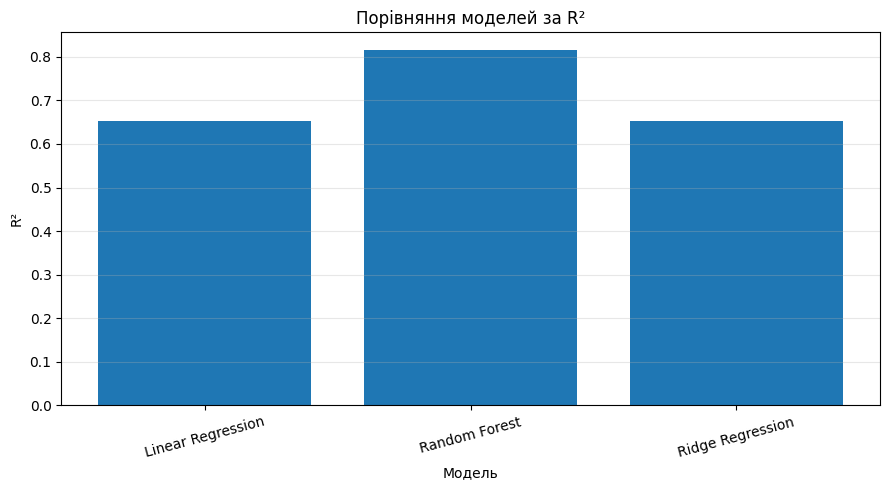

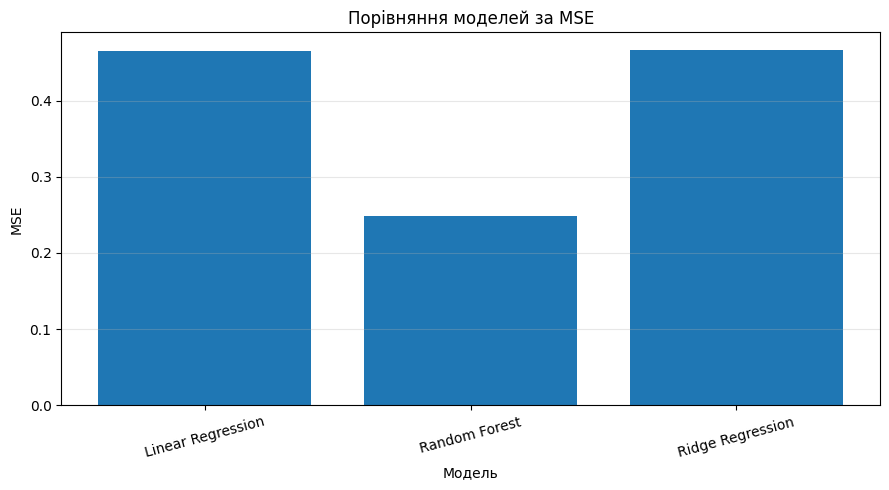

In [58]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import matplotlib.pyplot as plt

models_cal = {
    "Linear Regression": linear_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "Ridge Regression": ridge_search.best_estimator_
}

results_cal = []

# Оцінювання моделей
for name, model in models_cal.items():

    y_pred = model.predict(X_test_cal)

    r2 = r2_score(y_test_cal, y_pred)
    mse = mean_squared_error(y_test_cal, y_pred)

    results_cal.append({
        "Модель": name,
        "R²": round(r2, 4),
        "MSE": round(mse, 4)
    })

# Таблиця результатів
results_df_cal = pd.DataFrame(results_cal)

print("ПОРІВНЯННЯ МОДЕЛЕЙ НА ТЕСТОВІЙ ВИБІРЦІ")
display(results_df_cal)

# Графіки порівняння
plt.figure(figsize=(9, 5))

plt.bar(
    results_df_cal["Модель"],
    results_df_cal["R²"]
)

plt.title("Порівняння моделей за R²")
plt.xlabel("Модель")
plt.ylabel("R²")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

plt.bar(
    results_df_cal["Модель"],
    results_df_cal["MSE"]
)

plt.title("Порівняння моделей за MSE")
plt.xlabel("Модель")
plt.ylabel("MSE")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

№8 Вивести справжні і прогнозовані значення.

Найкраща модель за R²: Random Forest

Перші 10 результатів прогнозування:


,Справжнє значення,Прогнозоване значення
0,1.516,2.387954
1,0.992,1.092552
2,1.345,1.668090
3,2.317,1.863610
4,4.629,4.426298
5,1.407,2.014693
6,1.703,1.415620
7,1.603,1.810114
8,1.018,2.316638
9,1.688,1.442948


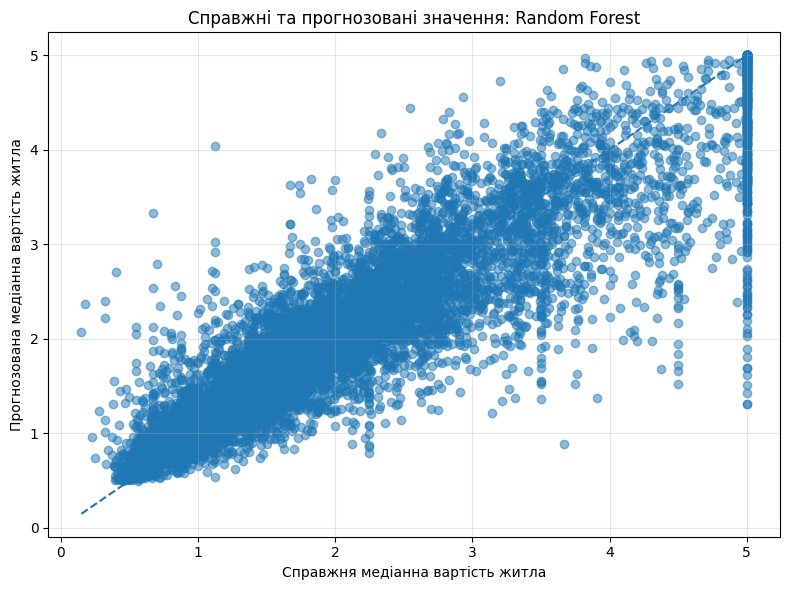

In [61]:
best_index_cal = results_df_cal["R²"].idxmax()

best_model_name_cal = results_df_cal.loc[
    best_index_cal, "Модель"
]

best_model_cal = models_cal[best_model_name_cal]

#Прогнозовані
y_pred_best_cal = best_model_cal.predict(X_test_cal)

comparison_cal = pd.DataFrame({
    "Справжнє значення": y_test_cal.values,
    "Прогнозоване значення": y_pred_best_cal
})

print("Найкраща модель за R²:", best_model_name_cal)


print("\nПерші 10 результатів прогнозування:")

#Графік прогнозування
display(comparison_cal.head(10))
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_cal,
    y_pred_best_cal,
    alpha=0.5
)

# Лінія ідеального прогнозування
min_value_cal = min(
    y_test_cal.min(),
    y_pred_best_cal.min()
)

max_value_cal = max(
    y_test_cal.max(),
    y_pred_best_cal.max()
)

plt.plot(
    [min_value_cal, max_value_cal],
    [min_value_cal, max_value_cal],
    linestyle="--"
)

plt.title(
    f"Справжні та прогнозовані значення: {best_model_name_cal}"
)

plt.xlabel("Справжня медіанна вартість житла")
plt.ylabel("Прогнозована медіанна вартість житла")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Висновок: У ході виконання другого завдання було проаналізовано набір даних California Housing Dataset: перевірено структуру, пропуски й дублікати, побудовано теплову карту кореляції та графік розподілу цільової змінної MedHouseVal. Дані поділено на тренувальну й тестову вибірки (50% / 50%), числові ознаки масштабовано за допомогою StandardScaler, а категоріальну ознаку ocean_proximity закодовано через OneHotEncoder.

Було побудовано три моделі регресії з підбором гіперпараметрів через GridSearchCV. Найкращий результат на тестовій вибірці показала модель Random Forest Regressor (max_depth = 15, min_samples_leaf = 2, n_estimators = 50) із R² = 0,0.7934 (на крос-валідації — 0,8156) та MSE = 0,2480.
Порівняння справжніх і прогнозованих значень підтвердило перевагу Random Forest Regressor: для цього набору даних модель випадкового лісу значно краще виявляє складні залежності між характеристиками районів і медіанною вартістю житла, ніж лінійні регресійні моделі.